# Lab L2-3：潛在空間的洞，和把洞補起來的 VAE（D2-3）

**需求單 #D2-3**（虛構公司：曜嶼電子，行銷科技組）：第四天要在一張 T4 上大量生成 512px 商品圖。
直接在像素上生成太貴；Stable Diffusion 先用 **VAE** 把影像壓小，再在小空間裡生成。今天先弄懂 VAE。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| 1 | Fashion-MNIST（代替型錄縮圖） | 真實樣本網格 |
| 2 | 同一個網路，兩種訓練：AE 與 VAE（潛在空間 2 維） | 兩條 loss |
| 3 | 把測試集畫在 2 維潛在空間 | 散佈圖：AE 有洞、VAE 比較滿 |
| 4 | 在潛在空間「隨便取點」解碼；兩件商品之間內插 | 網格、內插條 |
| 5 | 記憶檢查：生成的圖是不是在抄訓練集？ | 最近鄰對照 |
| 6 | Stable Diffusion 的 VAE：512×512 照片 → 64×64×4 → 還原 | 壓縮比、PSNR、時間、VRAM |

> 狀態：本筆記本尚未在 Colab T4 實跑（見 `research/lab-runs.md`）。

In [1]:
# 第 1 格：環境
%pip install -q -U diffusers accelerate
import torch, time, platform, random
import numpy as np
import matplotlib.pyplot as plt
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
EPOCHS = 15         # 沒有 GPU：改成 3

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 10.4 / 15.6 GB


## 1. 資料：Fashion-MNIST
10 類衣物與鞋包的 28×28 灰階照片（Zalando，MIT 授權），用來代替型錄縮圖：小、快、看得出好壞。

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.41MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.5MB/s]


訓練 60000 張｜測試 10000 張｜一張 (1, 28, 28)


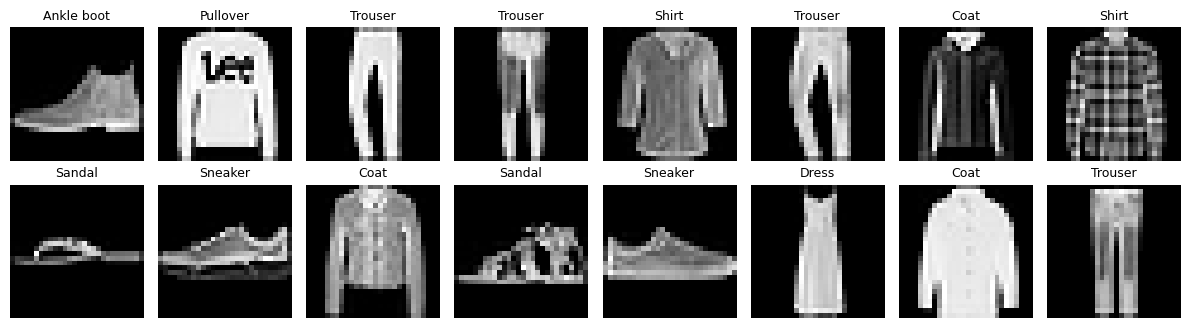

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

tf = transforms.ToTensor()                       # 0–1
train_ds = datasets.FashionMNIST("data", train=True, download=True, transform=tf)
test_ds = datasets.FashionMNIST("data", train=False, download=True, transform=tf)
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
X_test = torch.stack([test_ds[i][0] for i in range(len(test_ds))])     # [10000, 1, 28, 28]
y_test = test_ds.targets.clone()
print("訓練", len(train_ds), "張｜測試", len(test_ds), "張｜一張", tuple(X_test[0].shape))

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(X_test[i, 0], cmap="gray"); a.set_title(CLASSES[y_test[i]], fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig("fmnist_samples.png", dpi=120); plt.show()

## 2. 同一個網路，兩種訓練
- **AE**：編碼器輸出一個點 z，解碼器還原（D2-1 的做法）
- **VAE**：編碼器輸出一團雲的**中心 μ** 和**寬度 σ**（程式裡存 log σ²，叫 `logvar`）；z 從雲裡抽

重參數化（reparameterization）：`z = μ + σ · ε`，ε 從標準常態分布抽。隨機性放在 ε，梯度才流得回 μ 和 σ。

**先別執行下一格以後的散佈圖**：在投影片「練習：KL 會讓散佈圖變成什麼樣子？」寫下預測。

In [3]:
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):
    def __init__(self, latent=2, variational=True):
        super().__init__()
        self.variational = variational
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU())
        self.mu = nn.Linear(256, latent)
        self.logvar = nn.Linear(256, latent)
        self.dec = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        if not self.variational:
            return self.decode(mu), mu, logvar           # AE：直接用中心點
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + std * eps
        return self.decode(z), mu, logvar

def loss_fn(x_hat, x, mu, logvar, beta=1.0):
    """回傳 (總損失, 重建, KL)，都是「每張圖」的平均。"""
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / len(x)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)
    return recon + beta * kl, recon, kl

def train(model, beta, name):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); tot = rec = kls = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            x_hat, mu, logvar = model(xb)
            loss, r, k = loss_fn(x_hat, xb, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb); rec += r.item() * len(xb); kls += k.item() * len(xb)
        n = len(train_ds)
        if epoch in (1, EPOCHS) or epoch % 5 == 0:
            print(f"{name} epoch {epoch:2d}  總 {tot/n:7.2f} ＝ 重建 {rec/n:7.2f} ＋ {beta}×KL {kls/n:5.2f}  ({time.time()-t0:.0f}s)")
    return model

ae = train(VAE(variational=False).to(device), beta=0.0, name="AE ")
vae = train(VAE(variational=True).to(device), beta=1.0, name="VAE")

AE  epoch  1  總  276.43 ＝ 重建  276.43 ＋ 0.0×KL 17.96  (10s)
AE  epoch  5  總  252.14 ＝ 重建  252.14 ＋ 0.0×KL 15.12  (49s)
AE  epoch 10  總  249.20 ＝ 重建  249.20 ＋ 0.0×KL 11.18  (98s)
AE  epoch 15  總  247.72 ＝ 重建  247.72 ＋ 0.0×KL  8.70  (149s)
VAE epoch  1  總  289.39 ＝ 重建  283.14 ＋ 1.0×KL  6.25  (10s)
VAE epoch  5  總  260.76 ＝ 重建  254.43 ＋ 1.0×KL  6.33  (50s)
VAE epoch 10  總  257.69 ＝ 重建  251.21 ＋ 1.0×KL  6.48  (98s)
VAE epoch 15  總  256.02 ＝ 重建  249.44 ＋ 1.0×KL  6.58  (147s)


## 3. 潛在空間長什麼樣子？
把 10,000 張測試圖編碼成 2 維的點（VAE 用中心 μ），依類別上色。

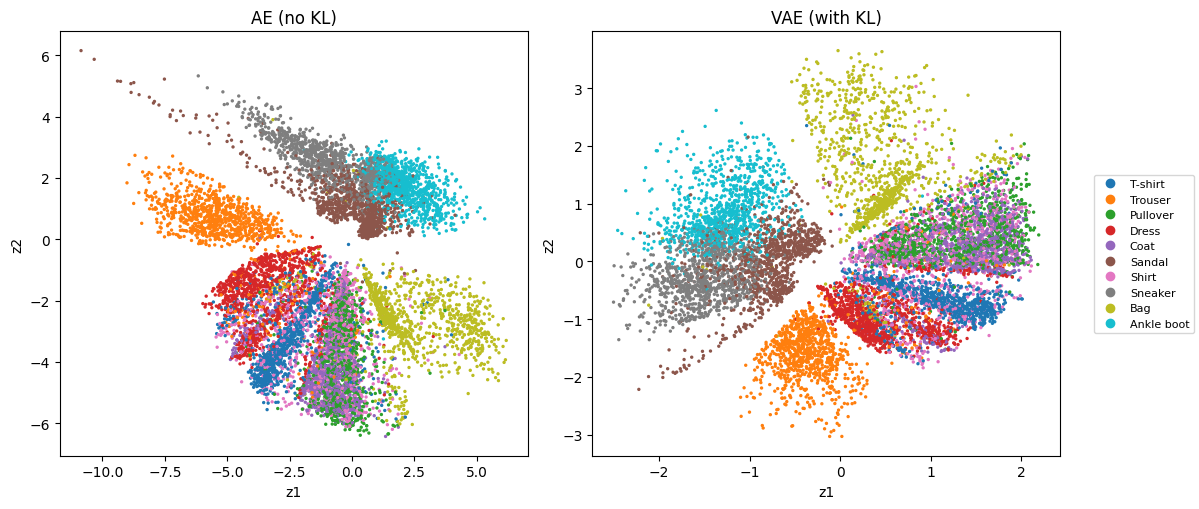

AE  潛在座標範圍：z1   -10.9 ～    6.2｜z2    -6.4 ～    6.1
VAE 潛在座標範圍：z1    -2.5 ～    2.2｜z2    -3.0 ～    3.7


In [4]:
@torch.no_grad()
def embed(model):
    model.eval()
    return torch.cat([model.encode(X_test[i:i + 1000].to(device))[0].cpu() for i in range(0, len(X_test), 1000)])

Z_ae, Z_vae = embed(ae), embed(vae)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, Z, t in zip(ax, [Z_ae, Z_vae], ["AE (no KL)", "VAE (with KL)"]):
    s = a.scatter(Z[:, 0], Z[:, 1], c=y_test, cmap="tab10", s=2)
    a.set_title(t); a.set_xlabel("z1"); a.set_ylabel("z2")
fig.legend(s.legend_elements()[0], CLASSES, loc="center right", fontsize=8)
plt.tight_layout(rect=(0, 0, 0.9, 1)); plt.savefig("latent_scatter.png", dpi=120); plt.show()
for name, Z in [("AE ", Z_ae), ("VAE", Z_vae)]:
    print(f"{name} 潛在座標範圍：z1 {Z[:,0].min():7.1f} ～ {Z[:,0].max():6.1f}｜z2 {Z[:,1].min():7.1f} ～ {Z[:,1].max():6.1f}")

## 4. 隨便取點解碼：洞在哪裡？
在 [-3, 3] × [-3, 3] 的方格上每隔一段取一個點，交給解碼器。
AE 的點可能根本不在這個範圍（看上一格印出的範圍）——這就是「洞」：沒有資料的地方，解碼器沒學過。

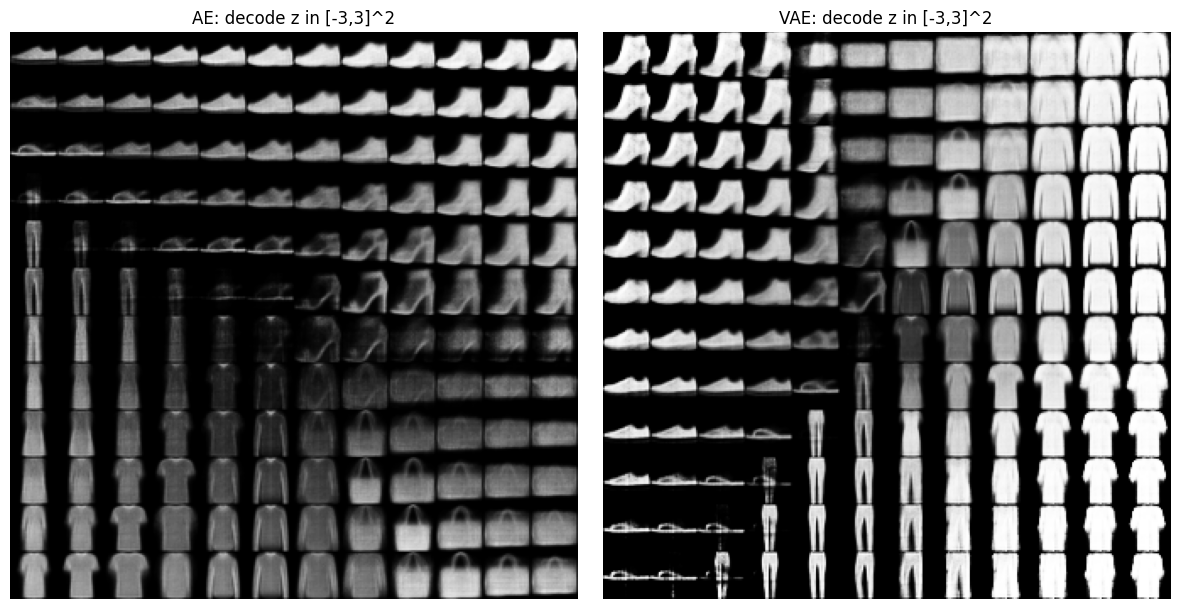

In [5]:
@torch.no_grad()
def decode_grid(model, n=12, r=3.0):
    model.eval()
    g = torch.linspace(-r, r, n)
    z = torch.stack(torch.meshgrid(g, -g, indexing="xy"), -1).view(-1, 2).to(device)
    imgs = model.decode(z).cpu().view(n, n, 28, 28)
    return imgs.permute(0, 2, 1, 3).reshape(n * 28, n * 28)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, m, t in zip(ax, [ae, vae], ["AE: decode z in [-3,3]^2", "VAE: decode z in [-3,3]^2"]):
    a.imshow(decode_grid(m), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig("latent_grid.png", dpi=120); plt.show()

**生成新商品**：從標準常態分布抽 z，交給 VAE 的解碼器。**內插**：兩件商品的 μ 之間取 10 個點。

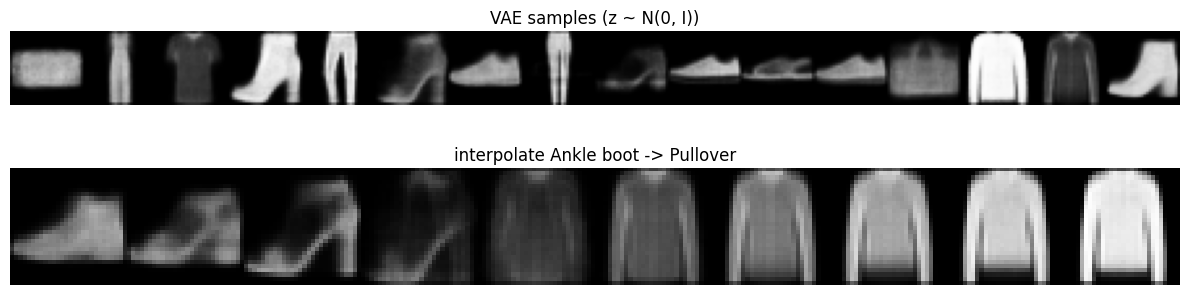

In [6]:
@torch.no_grad()
def sample(model, n=16):
    model.eval()
    z = torch.randn(n, 2, device=device)
    return model.decode(z).cpu()

torch.manual_seed(1)
S = sample(vae)
i, j = 0, 1                                   # 測試集第 0 張（Ankle boot）和第 1 張（Pullover）
with torch.no_grad():
    za, zb = Z_vae[i].to(device), Z_vae[j].to(device)
    strip = vae.decode(torch.stack([za + (zb - za) * t for t in torch.linspace(0, 1, 10, device=device)])).cpu()
fig, ax = plt.subplots(2, 1, figsize=(12, 3.6))
ax[0].imshow(torch.cat(list(S[:, 0]), 1), cmap="gray"); ax[0].set_title("VAE samples (z ~ N(0, I))"); ax[0].axis("off")
ax[1].imshow(torch.cat(list(strip[:, 0]), 1), cmap="gray"); ax[1].set_title(f"interpolate {CLASSES[y_test[i]]} -> {CLASSES[y_test[j]]}"); ax[1].axis("off")
plt.tight_layout(); plt.savefig("samples_interp.png", dpi=120); plt.show()

## 5. 記憶檢查（風險）：生成的圖是不是抄訓練集？
對每張生成的圖，找訓練集裡像素距離最近的一張。距離很小、長得一模一樣 → 模型在「背」訓練資料。

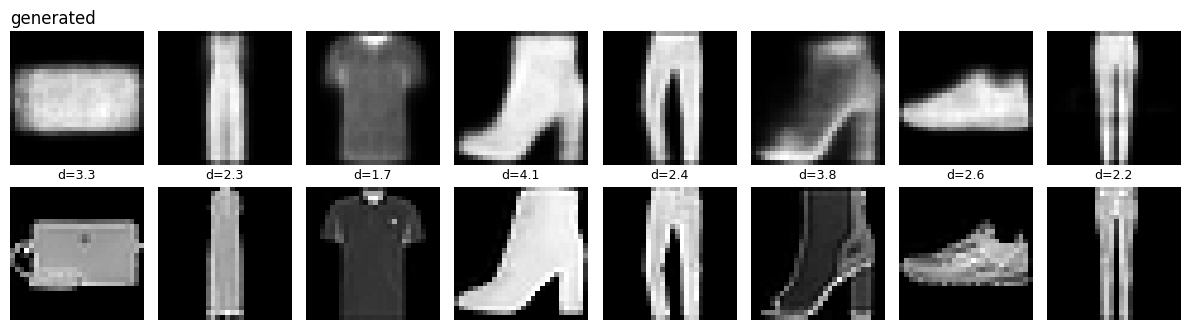

生成圖到最近訓練圖的平均距離 2.72（距離接近 0 而且長得一模一樣 → 在背訓練資料）


In [7]:
X_train = train_ds.data.float().div(255).view(len(train_ds), -1)      # [60000, 784]
with torch.no_grad():
    d = torch.cdist(S.view(len(S), -1), X_train)                     # [16, 60000]
    dist, idx = d.min(dim=1)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    ax[0, k].imshow(S[k, 0], cmap="gray"); ax[0, k].axis("off")
    ax[1, k].imshow(X_train[idx[k]].view(28, 28), cmap="gray"); ax[1, k].set_title(f"d={dist[k]:.1f}", fontsize=9); ax[1, k].axis("off")
ax[0, 0].set_title("generated", loc="left"); plt.tight_layout(); plt.savefig("nearest.png", dpi=120); plt.show()
print("生成圖到最近訓練圖的平均距離 %.2f（距離接近 0 而且長得一模一樣 → 在背訓練資料）" % dist.mean())

## 6. Stable Diffusion 的 VAE：512 × 512 照片能壓多小？
SD1.5 的 VAE（`AutoencoderKL`）：3 × 512 × 512 → **4 × 64 × 64** 的潛在表示，再還原。
照片：台北街景（lumoplank，CC0，Wikimedia Commons）；招牌上的小字最能看出壓縮損失。也可以換成你自己拍的照片。

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

輸入  (1, 3, 512, 512) → 潛在 (1, 4, 64, 64) → 還原 (1, 3, 512, 512)
數字個數：786,432 → 16,384，少了 48 倍
PSNR 20.6 dB｜編碼＋解碼 0.96 秒
VRAM 峰值 0.85 GB


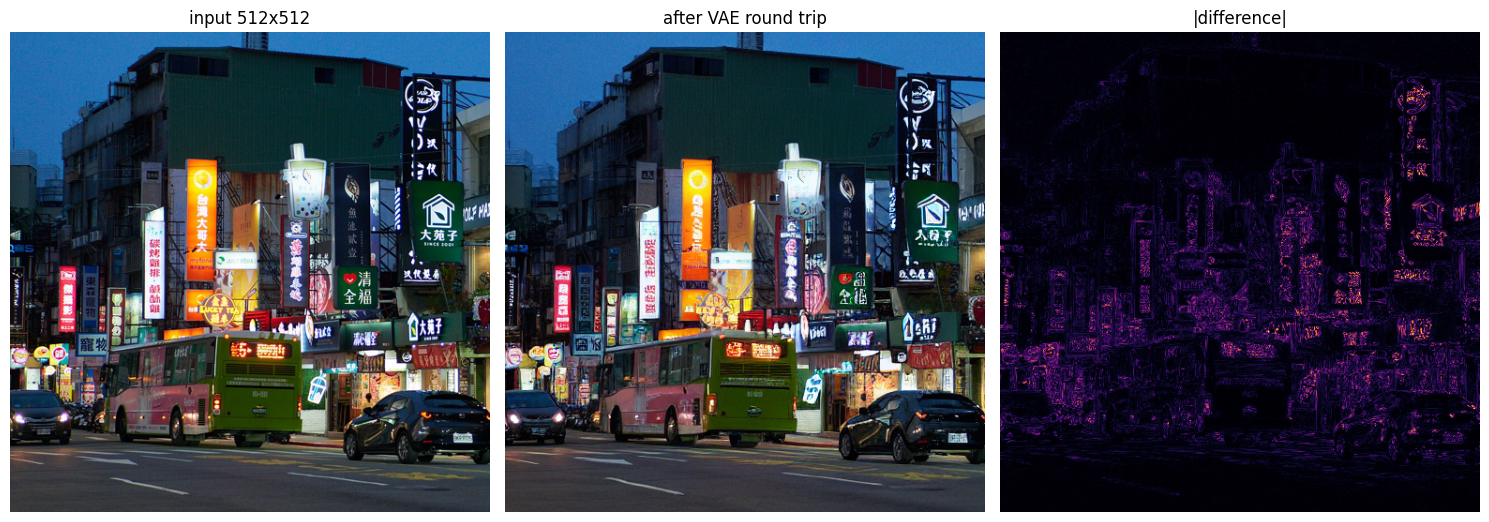

In [8]:
import io, urllib.request
from PIL import Image
from diffusers import AutoencoderKL

URL = "https://commons.wikimedia.org/wiki/Special:FilePath/Night_markets_of_Taipei_-_TaipeiNM4948.jpg?width=1024"
req = urllib.request.Request(URL, headers={"User-Agent": "gai-course-lab/1.0"})
photo = Image.open(io.BytesIO(urllib.request.urlopen(req).read())).convert("RGB")
w, h = photo.size; s = min(w, h)
photo = photo.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((512, 512))

dtype = torch.float16 if device == "cuda" else torch.float32
sd_vae = AutoencoderKL.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", subfolder="vae", torch_dtype=dtype).to(device)
x = transforms.ToTensor()(photo).unsqueeze(0).to(device, dtype) * 2 - 1      # SD 的 VAE 吃 −1～1

if device == "cuda":
    torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    lat = sd_vae.encode(x).latent_dist.mode()
    x_rec = sd_vae.decode(lat).sample
if device == "cuda":
    torch.cuda.synchronize()
sec = time.time() - t0

x01, r01 = (x.float() + 1) / 2, ((x_rec.float() + 1) / 2).clamp(0, 1)
mse = F.mse_loss(r01, x01).item()
print("輸入 ", tuple(x.shape), "→ 潛在", tuple(lat.shape), "→ 還原", tuple(x_rec.shape))
print(f"數字個數：{x[0].numel():,} → {lat[0].numel():,}，少了 {x[0].numel() / lat[0].numel():.0f} 倍")
print(f"PSNR {10 * np.log10(1 / mse):.1f} dB｜編碼＋解碼 {sec:.2f} 秒")
if device == "cuda":
    print(f"VRAM 峰值 {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

fig, ax = plt.subplots(1, 3, figsize=(15, 5.4))
ax[0].imshow(x01[0].permute(1, 2, 0).cpu()); ax[0].set_title("input 512x512")
ax[1].imshow(r01[0].permute(1, 2, 0).cpu()); ax[1].set_title("after VAE round trip")
ax[2].imshow((r01 - x01).abs()[0].mean(0).cpu(), cmap="inferno"); ax[2].set_title("|difference|")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("sd_vae_roundtrip.png", dpi=120); plt.show()